##### 3.1.3.10 cb_person_default_on_file

**Входы**

- Столбец cb_person_default_on_file после очистки

**Выходы**

- Таблицы, графики и наблюдения по признаку

**Что делаем**

Посмотрим, какие значения встречаются чаще и что выделяется на их фоне

In [ ]:
# dev-only: переходит в корень проекта; в сборку не входит
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_root = next(
    path for path in (_NotebookPath.cwd(), *_NotebookPath.cwd().parents)
    if (path / 'config/build/project.json').is_file()
)
_notebook_os.chdir(_notebook_root)


##### Прошлые дефолты — cb_person_default_on_file

N означает, что прошлых дефолтов не было, Y — что были. Посмотрим доли этих двух групп

,Количество,"Доля, %"
cb_person_default_on_file,,
N,26681,82.320817
Y,5730,17.679183


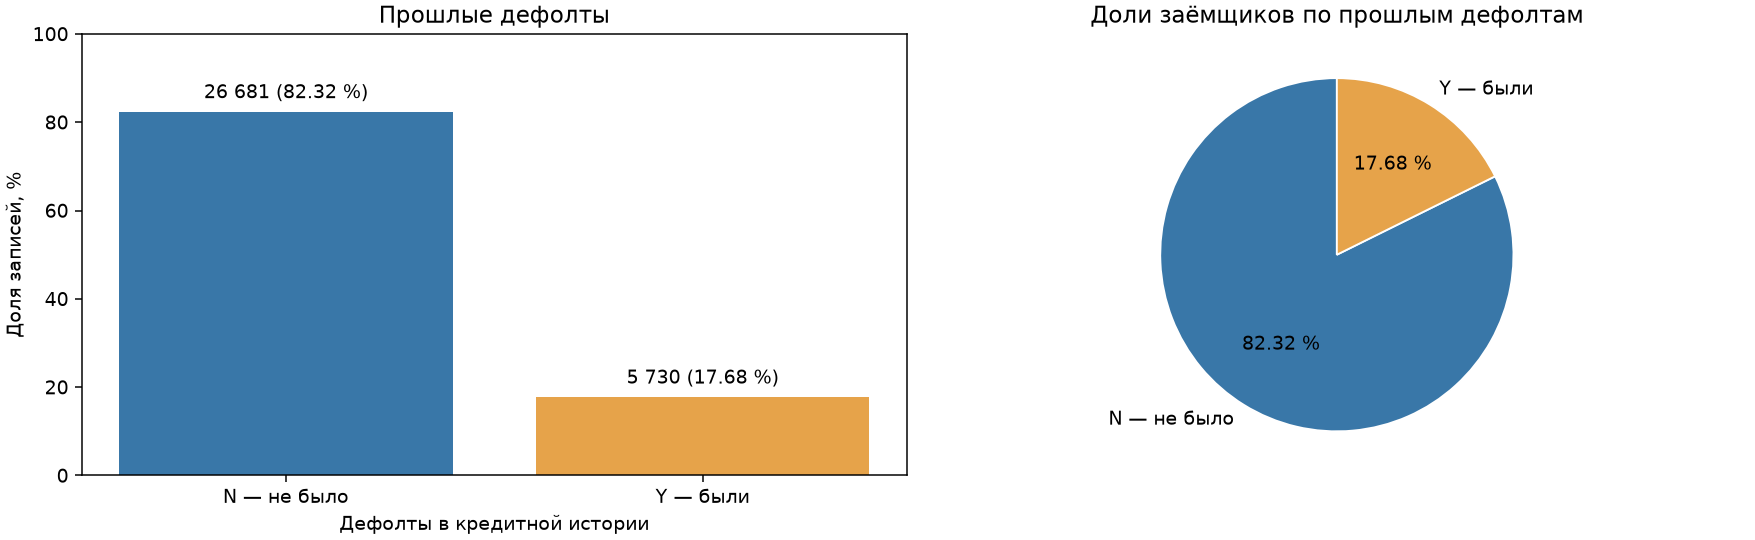

In [18]:
past_default_counts = data['cb_person_default_on_file'].value_counts().reindex(['N', 'Y'], fill_value=0)
past_default_table = pd.DataFrame({
    'Количество': past_default_counts,
    'Доля, %': 100 * past_default_counts / len(data),
})
display(past_default_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
past_default_labels = ['N — не было', 'Y — были']
past_default_colors = ['#3977a8', '#e6a34a']
bars = axes[0].bar(past_default_labels, past_default_table['Доля, %'], color=past_default_colors)
axes[0].bar_label(bars, labels=[
    f'{count:,} ({share:.2f} %)'.replace(',', ' ')
    for count, share in zip(past_default_table['Количество'], past_default_table['Доля, %'])
], padding=5)
axes[0].set(title='Прошлые дефолты', xlabel='Дефолты в кредитной истории', ylabel='Доля записей, %')
axes[0].set_ylim(0, 100)
axes[1].pie(past_default_counts, labels=past_default_labels, colors=past_default_colors,
            startangle=90, autopct=lambda share: f'{share:.2f} %',
            wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Доли заёмщиков по прошлым дефолтам')
plt.show()


**Выводы и решения по cb_person_default_on_file**

In [ ]:
conclusions = update_findings(conclusions, [
    ('f23', 'У большинства заёмщиков нет зарегистрированных прошлых дефолтов — N составляет 82,32 %, Y — 17,68 %', '—'),
])
display(findings_view(conclusions, only_new=True))